In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [2]:
data = {
    "Study_Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 2,
                    3, 5, 6, 7, 8, 1, 4, 6, 9, 5],
    "Attendance": [40, 50, 55, 65, 70, 75, 85, 90, 95, 45,
                   60, 72, 80, 88, 92, 35, 68, 78, 98, 74],
    "Internal_Marks": [20, 25, 30, 40, 50, 55, 70, 80, 95, 22,
                       35, 52, 60, 75, 85, 18, 45, 65, 98, 58]
}

df = pd.DataFrame(data)

df["Pass"] = (
    (df["Study_Hours"] >= 4) &
    (df["Attendance"] >= 65) &
    (df["Internal_Marks"] >= 40)
).astype(int)

df.head()

,Study_Hours,Attendance,Internal_Marks,Pass
0,1,40,20,0
1,2,50,25,0
2,3,55,30,0
3,4,65,40,1
4,5,70,50,1


In [3]:
X = df[["Study_Hours", "Attendance", "Internal_Marks"]]
y = df["Pass"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Scale the data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train the model
model = LogisticRegression()
model.fit(X_train_scaled, y_train)

predictions = model.predict(X_test_scaled)

print("Model Accuracy:", accuracy_score(y_test, predictions))

Model Accuracy: 0.8


In [4]:
import pickle

with open("student_model.pkl", "wb") as file:
    pickle.dump(model, file)

print("Model saved successfully!")

Model saved successfully!


In [5]:
with open("student_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

print("Model loaded successfully!")

Model loaded successfully!


In [6]:
import joblib

joblib.dump(model, "student_model.joblib")

print("Model saved using joblib!")

Model saved using joblib!


In [7]:
loaded_model = joblib.load("student_model.joblib")

print("Model loaded using joblib!")

Model loaded using joblib!


In [8]:
new_student = pd.DataFrame({
    "Study_Hours": [6],
    "Attendance": [80],
    "Internal_Marks": [65]
})

new_student_scaled = scaler.transform(new_student)

result = loaded_model.predict(new_student_scaled)

if result[0] == 1:
    print("Prediction: Student is likely to PASS")
else:
    print("Prediction: Student is likely to FAIL")

Prediction: Student is likely to PASS


In [9]:
joblib.dump(
    {"model": model, "scaler": scaler},
    "student_complete_model.joblib"
)

saved_data = joblib.load("student_complete_model.joblib")

loaded_model = saved_data["model"]
loaded_scaler = saved_data["scaler"]

print("Model and scaler loaded successfully!")

Model and scaler loaded successfully!


In [10]:
# Inputs
x = np.array([6, 80, 65])

# Weights and bias
weights = np.array([0.5, 0.02, 0.03])
bias = -3

# Weighted sum
z = np.dot(x, weights) + bias

print("Weighted Sum:", z)

Weighted Sum: 3.55


In [11]:
def step_function(x):
    return 1 if x >= 0 else 0

def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))

def relu(x):
    return max(0, x)

def tanh(x):
    return np.tanh(x)

print("Step:", step_function(z))
print("Sigmoid:", sigmoid(z))
print("ReLU:", relu(z))
print("Tanh:", tanh(z))

Step: 1
Sigmoid: 0.9720774262159271
ReLU: 3.55
Tanh: 0.9983511506272034


In [12]:
# Two input features
x = np.array([0.8, 0.6])

# Weights and bias for one neuron
weights = np.array([0.4, 0.7])
bias = 0.1

# Forward propagation
z = np.dot(x, weights) + bias
prediction = 1 / (1 + np.exp(-z))

print("Weighted Sum:", z)
print("Prediction:", prediction)

Weighted Sum: 0.84
Prediction: 0.6984652160025387


In [13]:
actual = 1
predicted = prediction

epsilon = 1e-7

loss = -(
    actual * np.log(predicted + epsilon)
    + (1 - actual) * np.log(1 - predicted + epsilon)
)

print("Binary Cross-Entropy Loss:", loss)

Binary Cross-Entropy Loss: 0.35886975648928127


In [14]:
# Demonstration of a single weight update

weight = 0.5
gradient = 0.2
learning_rate = 0.1

# SGD update
new_weight = weight - learning_rate * gradient

print("Old Weight:", weight)
print("Gradient:", gradient)
print("Updated Weight using SGD:", new_weight)

Old Weight: 0.5
Gradient: 0.2
Updated Weight using SGD: 0.48


In [15]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Two features: study effort and attendance
X = np.array([
    [0.1, 0.2],
    [0.2, 0.3],
    [0.3, 0.2],
    [0.4, 0.5],
    [0.5, 0.4],
    [0.6, 0.7],
    [0.7, 0.6],
    [0.8, 0.9],
    [0.9, 0.8],
    [0.9, 0.9],
    [0.2, 0.1],
    [0.3, 0.4]
])

# 0 = Fail, 1 = Pass
y = np.array([
    [0], [0], [0], [0], [0], [1],
    [1], [1], [1], [1], [0], [0]
])

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (12, 2)
Target shape: (12, 1)


In [16]:
np.random.seed(42)

input_size = 2
hidden_size = 4
output_size = 1

W1 = np.random.randn(input_size, hidden_size) * 0.1
b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, output_size) * 0.1
b2 = np.zeros((1, output_size))

print("W1 shape:", W1.shape)
print("W2 shape:", W2.shape)

W1 shape: (2, 4)
W2 shape: (4, 1)


In [17]:
def relu(z):
    return np.maximum(0, z)

def relu_derivative(z):
    return (z > 0).astype(float)

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def binary_cross_entropy(y_true, y_pred):
    eps = 1e-7
    y_pred = np.clip(y_pred, eps, 1 - eps)

    return -np.mean(
        y_true * np.log(y_pred)
        + (1 - y_true) * np.log(1 - y_pred)
    )

In [18]:
def forward_propagation(X, W1, b1, W2, b2):
    Z1 = X @ W1 + b1
    A1 = relu(Z1)

    Z2 = A1 @ W2 + b2
    A2 = sigmoid(Z2)

    cache = (X, Z1, A1, Z2, A2)

    return A2, cache

In [19]:
def backpropagation(y, cache, W2):
    X, Z1, A1, Z2, A2 = cache
    m = X.shape[0]

    # Output layer gradients
    dZ2 = (A2 - y) / m
    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    # Hidden layer gradients
    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * relu_derivative(Z1)
    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    return dW1, db1, dW2, db2

In [20]:
learning_rate = 0.5
epochs = 3000
loss_history = []

for epoch in range(epochs):
    # Forward pass
    predictions, cache = forward_propagation(X, W1, b1, W2, b2)

    # Calculate loss
    loss = binary_cross_entropy(y, predictions)
    loss_history.append(loss)

    # Backward pass
    dW1, db1, dW2, db2 = backpropagation(y, cache, W2)

    # Update weights and biases using SGD
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    if epoch % 500 == 0:
        print(f"Epoch {epoch}, Loss: {loss:.4f}")

print("Final Loss:", loss_history[-1])

Epoch 0, Loss: 0.6949
Epoch 500, Loss: 0.0081
Epoch 1000, Loss: 0.0028
Epoch 1500, Loss: 0.0016
Epoch 2000, Loss: 0.0011
Epoch 2500, Loss: 0.0008
Final Loss: 0.0006394427596357172


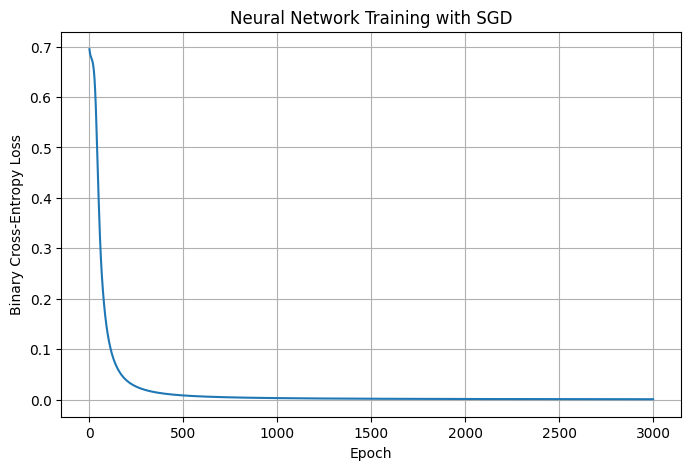

In [21]:
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Neural Network Training with SGD")
plt.grid()
plt.show()

In [22]:
predictions, _ = forward_propagation(X, W1, b1, W2, b2)

predicted_classes = (predictions >= 0.5).astype(int)

accuracy = np.mean(predicted_classes == y)

print("Actual values:    ", y.flatten())
print("Predicted values: ", predicted_classes.flatten())
print(f"Training Accuracy: {accuracy * 100:.2f}%")

Actual values:     [0 0 0 0 0 1 1 1 1 1 0 0]
Predicted values:  [0 0 0 0 0 1 1 1 1 1 0 0]
Training Accuracy: 100.00%


In [23]:
np.random.seed(42)

W1 = np.random.randn(2, 4) * 0.1
b1 = np.zeros((1, 4))
W2 = np.random.randn(4, 1) * 0.1
b2 = np.zeros((1, 1))

params = {"W1": W1, "b1": b1, "W2": W2, "b2": b2}

m_avg = {k: np.zeros_like(v) for k, v in params.items()}
v_avg = {k: np.zeros_like(v) for k, v in params.items()}

beta1 = 0.9
beta2 = 0.999
epsilon = 1e-8
learning_rate = 0.01
epochs = 3000
adam_loss_history = []

for t in range(1, epochs + 1):
    predictions, cache = forward_propagation(
        X, params["W1"], params["b1"],
        params["W2"], params["b2"]
    )

    loss = binary_cross_entropy(y, predictions)
    adam_loss_history.append(loss)

    dW1, db1, dW2, db2 = backpropagation(
        y, cache, params["W2"]
    )

    grads = {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}

    for key in params:
        g = grads[key]

        m_avg[key] = beta1 * m_avg[key] + (1 - beta1) * g
        v_avg[key] = beta2 * v_avg[key] + (1 - beta2) * (g ** 2)

        m_hat = m_avg[key] / (1 - beta1 ** t)
        v_hat = v_avg[key] / (1 - beta2 ** t)

        params[key] -= (
            learning_rate * m_hat /
            (np.sqrt(v_hat) + epsilon)
        )

    if t % 500 == 0:
        print(f"Epoch {t}, Loss: {loss:.4f}")

print("Final Adam Loss:", adam_loss_history[-1])

Epoch 500, Loss: 0.0099
Epoch 1000, Loss: 0.0022
Epoch 1500, Loss: 0.0009
Epoch 2000, Loss: 0.0005
Epoch 2500, Loss: 0.0003
Epoch 3000, Loss: 0.0002
Final Adam Loss: 0.00019039525282163144


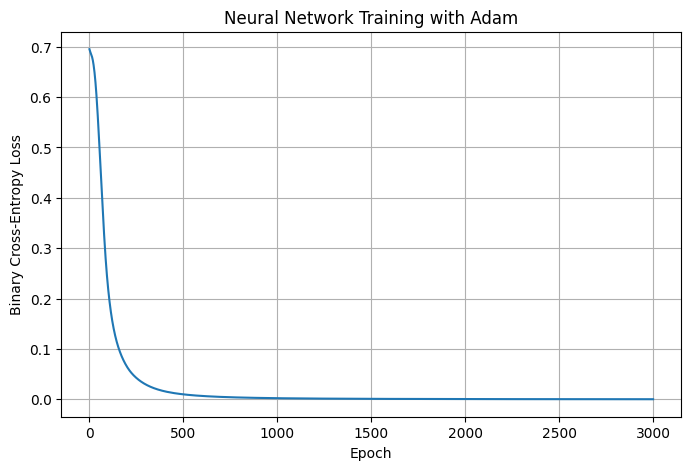

In [24]:
plt.figure(figsize=(8, 5))
plt.plot(adam_loss_history)
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Neural Network Training with Adam")
plt.grid()
plt.show()